# 02 — K-means Clustering & Customer Segmentation (Member 3)

**Question:** can a retailer separate loyal customers, occasional shoppers and customers who may have stopped buying?

Input: `data/processed/customer_features.csv` from Member 1 (one row per customer, observation window 2010-12-01 → 2011-05-31).
All logic lives in `src/clustering.py`; this notebook runs it step by step and explains the choices.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import clustering as cl

df = cl.load_features()
df.shape

(2718, 9)

## 1. Feature selection
We cluster on the three classic **RFM** features: `recency_days`, `frequency`, `monetary`. They map directly to the business question (how recently, how often, how much) and keep segments easy to explain. The other engineered features are used afterwards to *profile* the segments.

In [2]:
df[list(cl.CLUSTER_FEATURES)].describe().round(2)

,recency_days,frequency,monetary
count,2718.00,2718.00,2718.00
mean,63.97,2.73,1223.11
std,52.39,4.03,4121.34
min,1.00,1.00,2.90
25%,20.00,1.00,240.02
50%,50.00,2.00,475.08
75%,97.00,3.00,1064.76
max,182.00,86.00,110713.12


## 2. Scaling
All three are strongly right-skewed (a few very large spenders). K-means uses Euclidean distance, so we apply `log1p` and then `StandardScaler` so that no single feature or outlier dominates.

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for i, c in enumerate(cl.CLUSTER_FEATURES):
    axes[0, i].hist(df[c], bins=50); axes[0, i].set_title(f'{c} (raw)')
    axes[1, i].hist(np.log1p(df[c]), bins=50, color='tab:orange'); axes[1, i].set_title(f'log1p({c})')
plt.tight_layout(); plt.show()
print('skew raw:', df[list(cl.CLUSTER_FEATURES)].skew().round(2).to_dict())
print('skew log:', np.log1p(df[list(cl.CLUSTER_FEATURES)]).skew().round(2).to_dict())

skew raw: {'recency_days': 0.8, 'frequency': 8.34, 'monetary': 14.55}
skew log: {'recency_days': -0.62, 'frequency': 1.62, 'monetary': 0.44}


C:\Users\anish\AppData\Local\Temp\ipykernel_17272\937267798.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 3. Choosing k (elbow + silhouette)
We fit K-means for k = 2…10 (`n_init=20`, `random_state=42`).

In [4]:
scores = cl.evaluate_k(df[list(cl.CLUSTER_FEATURES)])
scores.round(3)

,k,inertia,silhouette
0,2,4255.503,0.442
1,3,3205.577,0.353
2,4,2567.715,0.354
3,5,2152.478,0.332
4,6,1925.805,0.282
5,7,1751.253,0.278
6,8,1618.604,0.271
7,9,1497.706,0.275
8,10,1397.675,0.273


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scores.k, scores.inertia, marker='o'); axes[0].set_title('Elbow (inertia)')
axes[1].plot(scores.k, scores.silhouette, marker='o'); axes[1].set_title('Silhouette score')
for a in axes: a.axvline(cl.DEFAULT_K, color='red', ls='--'); a.set_xlabel('k')
plt.tight_layout(); plt.show()

C:\Users\anish\AppData\Local\Temp\ipykernel_17272\404549069.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


**Choice: k = 4.** k = 2 has the highest silhouette but only splits customers into "active" vs "inactive", which cannot distinguish loyal from occasional buyers. The silhouette at k = 4 is essentially equal to k = 3 and clearly higher than k ≥ 5, and the elbow curve flattens after about k = 4. So k = 4 is the best trade-off between cluster quality and business usefulness.

## 4. Fit final model, name segments, export artifacts

In [6]:
meta = cl.run_clustering(k=cl.DEFAULT_K)
print('k =', meta['k'], '| silhouette =', meta['silhouette_at_k'])
pd.DataFrame(meta['centroids_original_units']).T.assign(segment=lambda d: d.index.map(meta['segment_names']))

k = 4 | silhouette = 0.354


,recency_days,frequency,monetary,segment
0,93.38,1.08,216.01,Lapsed / At-Risk
1,55.20,2.46,956.23,Cooling Off
2,11.98,7.44,2926.53,Loyal Champions
3,12.60,1.77,452.52,Occasional Shoppers


Segments are named from their centroids: highest RFM score → **Loyal Champions**, lowest → **Lapsed / At-Risk**; the middle clusters are **Occasional Shoppers** (bought recently but rarely) and **Cooling Off** (used to spend but haven't returned lately).

## 5. Segment profiles

In [7]:
summary = pd.read_csv('results/clustering/segment_summary.csv')
summary

,cluster,segment,customers,share_pct,mean_recency_days,mean_frequency,mean_monetary,mean_distinct_products,mean_active_purchase_days,mean_average_invoice_value,mean_average_items_per_invoice,mean_customer_tenure_days,median_recency_days,median_frequency,median_monetary
0,2,Loyal Champions,386,14.2,15.99,8.86,4951.11,105.86,7.53,573.67,314.42,141.48,13.0,7.0,2606.82
1,1,Cooling Off,648,23.8,64.13,2.62,1235.25,52.22,2.45,646.08,421.99,67.94,55.0,2.0,913.62
2,3,Occasional Shoppers,558,20.5,15.08,1.90,574.80,31.46,1.82,334.29,193.78,51.77,14.0,2.0,474.37
3,0,Lapsed / At-Risk,1126,41.4,104.56,1.09,259.42,18.71,1.07,247.03,142.52,3.71,97.0,1.0,233.18


## 6. Visualisations

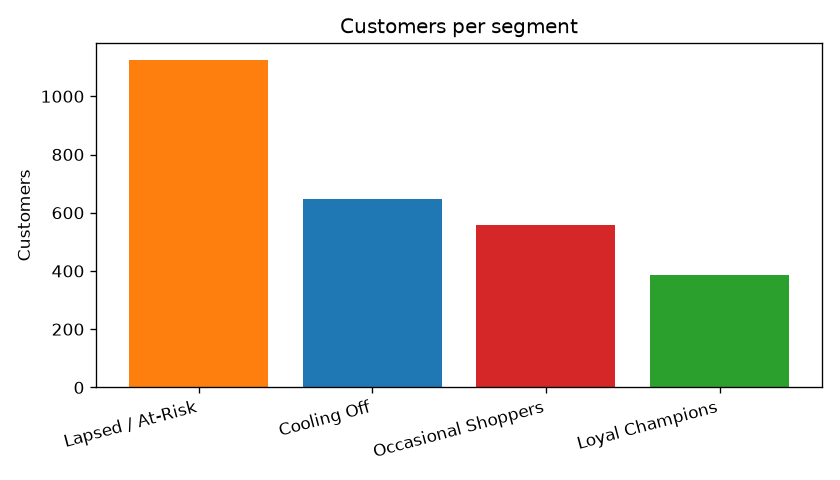

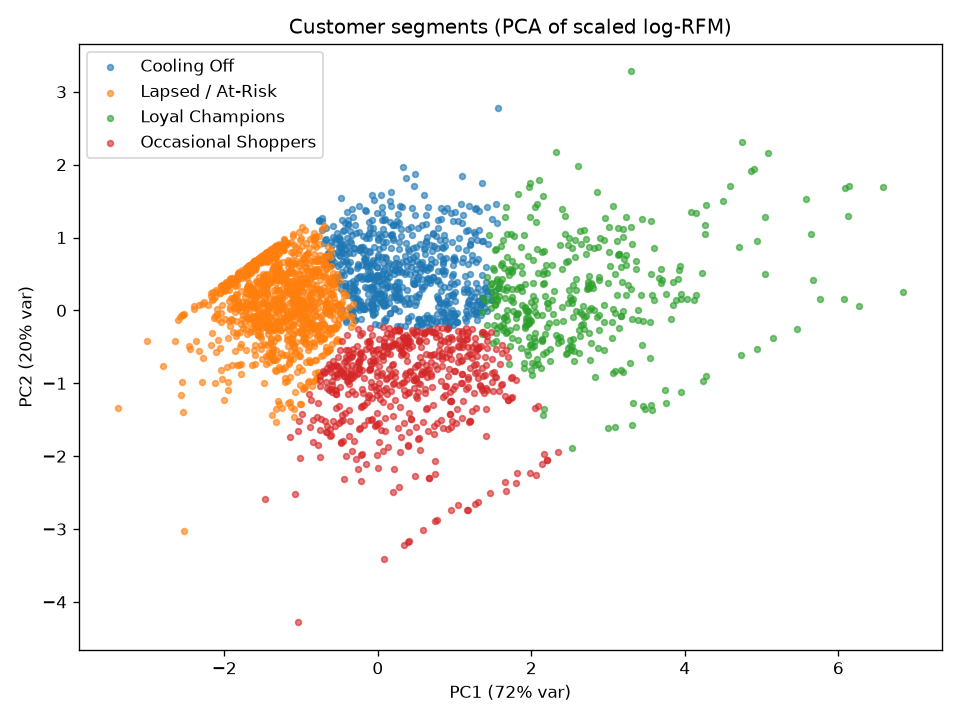

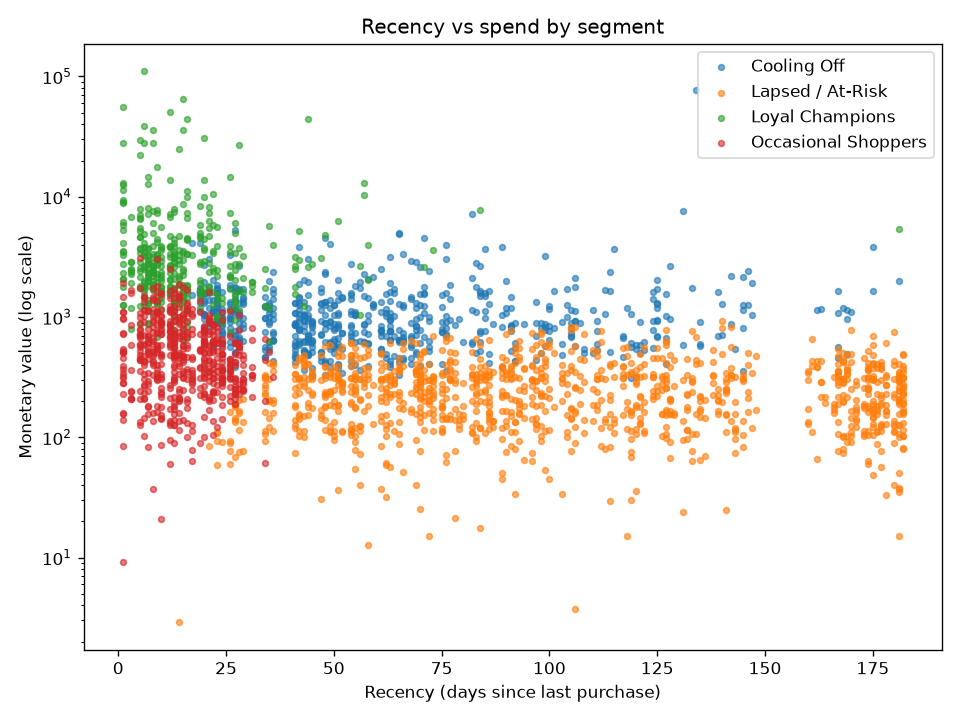

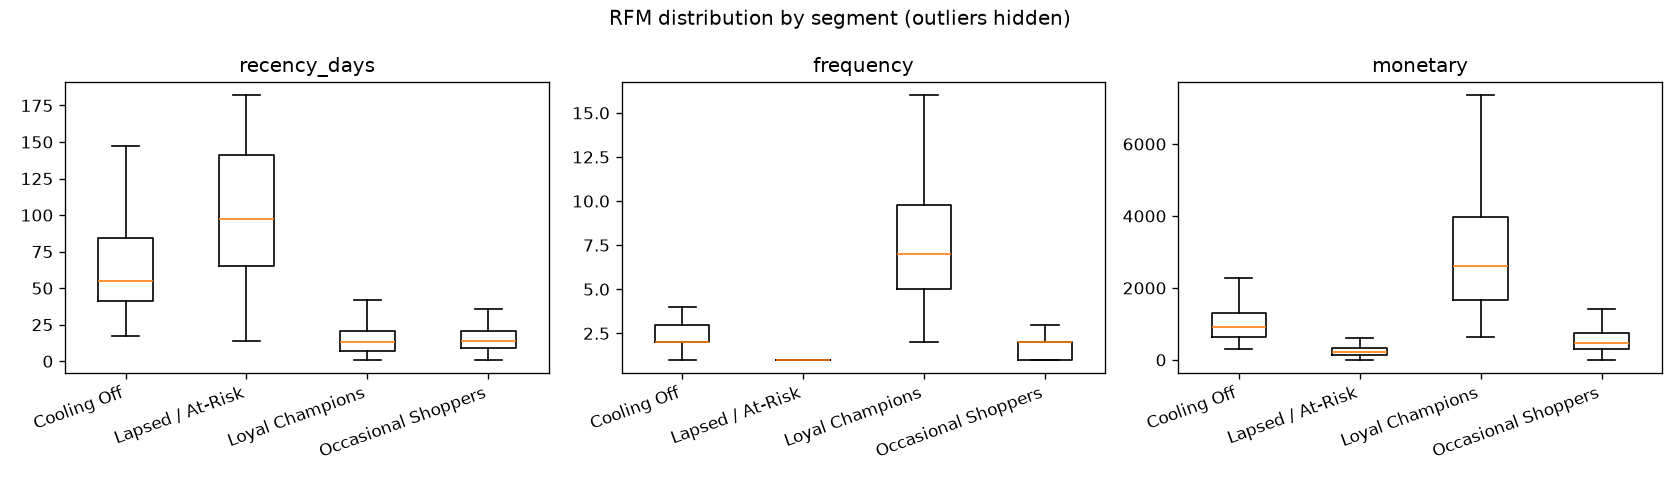

In [8]:
for f in ['segment_sizes', 'segments_pca', 'segments_recency_monetary', 'segment_rfm_boxplots']:
    display(Image(f'results/clustering/{f}.png'))

## 7. Does segmentation agree with the supervised target?
As a sanity check we join segments to Member 1/2's `repeat_purchase` label (did the customer buy again in Jun–Aug 2011). This label was **not** used for clustering.

In [9]:
import glob
parts = [pd.read_csv(p) for p in glob.glob('data/processed/*.csv') if os.path.basename(p) in ('train.csv','validation.csv','test.csv')]
if parts:
    lab = pd.concat(parts)[['CustomerID', 'repeat_purchase']]
    a = pd.read_csv('results/clustering/cluster_assignments.csv').merge(lab, on='CustomerID')
    display(a.groupby('segment')['repeat_purchase'].agg(['count', 'mean']).rename(columns={'mean': 'repeat_rate'}).sort_values('repeat_rate', ascending=False).round(3))
else:
    print('Split CSVs not found — run the src.features pipeline to enable this check.')

Split CSVs not found — run the src.features pipeline to enable this check.


## 8. Using the model in the UI (for Member 4)
```python
from src.clustering import load_segmenter, predict_segment
pipe, names = load_segmenter()
predict_segment(recency_days=10, frequency=8, monetary=3000, pipe=pipe, names=names)
```

In [10]:
pipe, names = cl.load_segmenter()
for r, f, m in [(10, 8, 3000), (15, 2, 400), (60, 3, 1200), (120, 1, 150)]:
    print((r, f, m), '->', cl.predict_segment(r, f, m, pipe, names))

(10, 8, 3000) -> (2, 'Loyal Champions')
(15, 2, 400) -> (3, 'Occasional Shoppers')
(60, 3, 1200) -> (1, 'Cooling Off')
(120, 1, 150) -> (0, 'Lapsed / At-Risk')


## 9. Limitations
- K-means assumes roughly spherical clusters of similar size; RFM data is continuous, so segment boundaries are soft (silhouette ≈ 0.35).
- Segments describe a single 6-month window; they should be refit on newer data.
- Segment names are heuristic labels derived from centroids, not ground truth.